# 10 — Painel descritivo: drift observado e resposta simulada

> **Modelo congelado:** `scale_pos_weight=13.882494684620836`; corte 0,50 usado apenas nas referências de decisão. A suíte anterior permanece separada.

**Pergunta.** Como situar o drift marginal de `cs-test.csv` diante da variabilidade amostral e das curvas de desempenho simulado dos notebooks 04 e 05? Este painel **não define critérios de parada, semáforos nem alertas automáticos**.

1. Reconstituímos o holdout rotulado e calculamos Brier, AUC ROC, PR-AUC trapezoidal e KS do modelo. Scores de `cs-test` são descritos sem atribuir a ele métricas de desempenho: seus rótulos estão ausentes.
2. Calculamos PSI de cada entrada e do score com bins **fixados no holdout**, exatamente como no 04. Uma simulação multinomial com os tamanhos das amostras fornece quantis descritivos da variação de PSI sob igualdade marginal; ela não informa materialidade de negócio.
3. Para cada entrada, recuperamos do CSV detalhado de 04 os cenários com PSI mais próximo do observado. Mostramos intervalo de deltas das quatro métricas e a **distância entre PSI observado e simulado mais próximo**. Um PSI parecido não identifica a mesma direção ou forma de drift; portanto a comparação serve para exploração, não para prever desempenho em `cs-test`.
4. Em separado, visualizamos as respostas multivariadas da **metade de confirmação** em 05 versus PSI dos 16 grupos conjuntos. Esse PSI conjunto tem outra discretização e não deve ser comparado numericamente ao PSI marginal de `cs-test`.

A interpretação depende de $P(Y\mid X)$ permanecer estável, cobertura de perfis e validação em uma safra futura rotulada. Os cenários de 04/05 reponderam linhas históricas completas; `cs-test` é uma população observada sem desfecho.

In [1]:
from pathlib import Path

# Resolve o projeto tanto pelo Jupyter aberto em notebooks/ quanto pelo executor.
_inicio = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in (_inicio, *_inicio.parents)
     if (p / "models" / "manifesto_modelo.json").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Não encontrei models/manifesto_modelo.json. Abra o projeto clonado.")
DATA_DIR_PROJECT = PROJECT_ROOT / "data" / "raw"
MODEL_DIR = PROJECT_ROOT / "models"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
for _nome in ("cs-training.csv", "cs-test.csv"):
    if not (DATA_DIR_PROJECT / _nome).is_file():
        raise FileNotFoundError(
            f"Falta {DATA_DIR_PROJECT / _nome}. Veja README.md, seção Dados."
        )


## 1. Entradas do painel e decisões de desenho

`N_SIMULACOES` controla a precisão dos quantis descritivos da distribuição nula de PSI; os quantis 5%, 50% e 95% são uma **faixa de contexto**, sem regra de aprovação. `N_VIZINHOS_PSI` indica quantos cenários do 04 usamos para contextualizar cada PSI observado; alterar esse número muda o resumo. `k=20` é uma escolha de visualização, não um nível de significância. A comparação exata também exige examinar a trajetória, direção, ESS e covariáveis colaterais no CSV original.

In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, precision_recall_curve, auc as area_curva

SEMENTE = 33
N_SIMULACOES = 10_000
N_VIZINHOS_PSI = 20
P = DATA_DIR_PROJECT
DATA_DIR = next((d for d in (P, P.parent) if (d / 'cs-training.csv').is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError('Abra a partir da pasta do projeto ou notebooks/; ajuste DATA_DIR.')
OUT_DIR = TABLES_DIR
ARQUIVO_MODELO = MODEL_DIR / 'model_class_retreinado.json'
ARQUIVO_UNI = OUT_DIR / 'resultados_univariado_extensivo.csv'
ARQUIVO_MULTI = OUT_DIR / 'resultados_multivariado_populacional.csv'
MANIFESTO = json.loads((MODEL_DIR / 'manifesto_modelo.json').read_text(encoding='utf-8'))
FEATURES = MANIFESTO['features']
ALVO = MANIFESTO['target']
assert all(p.exists() for p in (ARQUIVO_MODELO,ARQUIVO_UNI,ARQUIVO_MULTI)), 'Execute 00, 04 e 05 antes de 10.'
sns.set_theme(style='whitegrid', context='notebook')
print('Dados:', DATA_DIR)
print('Booster:', MANIFESTO['status'])
print('Simulações nulas por painel:', N_SIMULACOES, '| vizinhos de PSI:', N_VIZINHOS_PSI)

Dados: .\data\raw
Booster: retreino com scale_pos_weight=13.882494684620836; nao e o Booster original
Simulações nulas por painel: 10000 | vizinhos de PSI: 20


In [3]:
# Verifica que o modelo, o manifesto e a configuração deste estudo coincidem.
import hashlib as _hashlib
import json as _json
_manifesto_versao = _json.loads(
    (MODEL_DIR / "manifesto_modelo.json").read_text(encoding="utf-8")
)
assert abs(_manifesto_versao["params_fornecidos"]["scale_pos_weight"]
           - 13.882494684620836) < 1e-12
assert _manifesto_versao["cutoff"] == 0.5
assert _manifesto_versao["features"] == FEATURES
_arquivo_modelo_versao = MODEL_DIR / "model_class_retreinado.json"
assert _hashlib.sha256(_arquivo_modelo_versao.read_bytes()).hexdigest() == \
       _manifesto_versao["model_sha256"], "Booster e manifesto divergentes."
print("Modelo validado:", _manifesto_versao["variant"])


Modelo validado: metricas_brier_auc_prauc_ks_grade_5a50


## 2. Recriar a referência e conferir o modelo

O split de 15% é aleatório e sem estratificação; não é uma amostra fora do tempo. O Booster é o retreino congelado do notebook 00. As quatro métricas centrais usam **somente** o holdout rotulado. Em `cs-test.csv`, exibimos tamanho, score médio e proporção acima de 0,50, sem Brier/AUC/PR-AUC/KS, recall ou precisão.

In [4]:
bruto = pd.read_csv(DATA_DIR / 'cs-training.csv').drop(columns='Unnamed: 0')
alvo = pd.read_csv(DATA_DIR / 'cs-test.csv').drop(columns='Unnamed: 0')
assert list(bruto[FEATURES].columns) == FEATURES
assert bruto[ALVO].notna().all() and alvo[ALVO].isna().all()
X_trval, X_hold, y_trval, y_hold = train_test_split(
    bruto[FEATURES], bruto[ALVO].astype(int), test_size=0.15, random_state=SEMENTE)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_trval, y_trval, test_size=0.1765, random_state=SEMENTE)
assert (len(X_tr), len(X_val), len(X_hold), len(alvo)) == (104996, 22504, 22500, 101503)
modelo = xgb.Booster()
modelo.load_model(str(ARQUIVO_MODELO))
modelo.set_param({'device': 'cpu'})
assert modelo.num_boosted_rounds() == MANIFESTO['num_boosted_rounds']
assert modelo.feature_names in (None, FEATURES)

def escorar(X):
    d = xgb.DMatrix(X[FEATURES], feature_names=FEATURES, enable_categorical=True)
    return np.asarray(modelo.predict(d), dtype=float)

p_hold = escorar(X_hold)
p_alvo = escorar(alvo)
fpr,tpr,_=roc_curve(y_hold,p_hold)
precision_curve,recall_curve,_=precision_recall_curve(y_hold,p_hold)
baseline={'brier':float(np.mean((np.asarray(y_hold)-p_hold)**2)),
          'auc':float(area_curva(fpr,tpr)),
          'prauc_trap':float(area_curva(recall_curve,precision_curve)),
          'ks_modelo':float(np.max(tpr-fpr))}
for k,manifest_key in [('brier','brier'),('auc','auc_roc'),
                       ('prauc_trap','pr_auc_trap'),('ks_modelo','ks_modelo')]:
    assert np.isclose(baseline[k],MANIFESTO['baseline_holdout'][manifest_key],atol=1e-6)
display(pd.DataFrame({
    'populacao': ['holdout rotulado', 'cs-test sem rótulos'],
    'n': [len(X_hold), len(alvo)],
    'prevalencia_observada': [float(y_hold.mean()), np.nan],
    'score_medio': [float(p_hold.mean()), float(p_alvo.mean())],
    'fracao_score_ge_0_5': [float((p_hold>=.5).mean()), float((p_alvo>=.5).mean())],
    'brier':[baseline['brier'],np.nan],
    'auc_roc':[baseline['auc'],np.nan],
    'pr_auc_trapezoidal':[baseline['prauc_trap'],np.nan],
    'ks_modelo':[baseline['ks_modelo'],np.nan]
}).round(5))

,populacao,n,prevalencia_observada,score_medio,fracao_score_ge_0_5,brier,auc_roc,pr_auc_trapezoidal,ks_modelo
0,holdout rotulado,22500,0.06667,0.32400,0.24591,0.14404,0.86684,0.39599,0.58771
1,cs-test sem rótulos,101503,NaN,0.32244,0.24195,NaN,NaN,NaN,NaN


## 3. PSI marginal e variação esperada por tamanho amostral

Para cada coluna, os cortes são os quantis do **holdout sem pesos** em 1%, 5%, 10%, …, 90%, 95% e 99%, com cortes repetidos removidos e uma classe de não finitos. Isto reproduz a função do 04: `searchsorted(..., side='left')` para observados e $\varepsilon=10^{-9}$ no logaritmo do PSI. Se $p_b$ e $q_b$ são as proporções nos bins fixos, $\mathrm{PSI}=\sum_b(q_b-p_b)\ln[(q_b+\varepsilon)/(p_b+\varepsilon)]$.

Sob hipótese simplificada de mesma distribuição marginal e linhas independentes, sorteamos contagens multinomiais nos tamanhos de 22.500 e 101.503, usando a distribuição agrupada. Os percentis 5/50/95 da simulação descrevem a amplitude de flutuação **neste modelo nulo**, sem classificar o PSI observado. Dependência por safra, sazonalidade, escolha dos bins e dados coletados seletivamente podem ampliar a variabilidade real. PSI não mostra a direção nem o bin responsável; médias, faltantes e quantis acompanham a tabela.

In [5]:
def codigos_bins(referencia, comparacao):
    ref=np.asarray(referencia,dtype=float); cmp=np.asarray(comparacao,dtype=float)
    cortes=np.unique(np.quantile(ref[np.isfinite(ref)],
                     np.r_[.01,.05,np.linspace(.1,.9,9),.95,.99]))
    def ids(x):
        z=np.full(len(x),len(cortes)+1,dtype=int)
        presente=np.isfinite(x)
        z[presente]=np.searchsorted(cortes,x[presente],side='left')
        return z
    return ids(ref),ids(cmp),len(cortes)+2

def psi_proporcoes(a,b):
    eps=1e-9
    return np.sum((b-a)*np.log((b+eps)/(a+eps)),axis=0)

def avaliar_psi(nome,referencia,comparacao,gerador):
    ir,ic,k=codigos_bins(referencia,comparacao)
    nr,nc=len(ir),len(ic)
    p=np.bincount(ir,minlength=k)/nr
    q=np.bincount(ic,minlength=k)/nc
    observado=float(psi_proporcoes(p,q))
    comum=(p*nr+q*nc)/(nr+nc)
    a=gerador.multinomial(nr,comum,size=N_SIMULACOES).T/nr
    b=gerador.multinomial(nc,comum,size=N_SIMULACOES).T/nc
    psi_nulo=psi_proporcoes(a,b)
    return {'variavel':nome,'psi_observado':observado,
            'psi_nulo_p05':float(np.quantile(psi_nulo,.05)),
            'psi_nulo_mediana':float(np.median(psi_nulo)),
            'psi_nulo_p95':float(np.quantile(psi_nulo,.95)),
            'n_bins_incluindo_nao_finitos':k,
            'media_referencia':float(np.nanmean(referencia)),
            'media_cs_test':float(np.nanmean(comparacao)),
            'ausentes_referencia':float(np.mean(~np.isfinite(referencia))),
            'ausentes_cs_test':float(np.mean(~np.isfinite(comparacao)))}

rng=np.random.default_rng(SEMENTE+10)
linhas=[avaliar_psi(f,X_hold[f],alvo[f],rng) for f in FEATURES]
linhas.append(avaliar_psi('score_modelo',p_hold,p_alvo,rng))
monitor=pd.DataFrame(linhas)
display(monitor[['variavel','psi_observado','psi_nulo_p05','psi_nulo_mediana','psi_nulo_p95',
                 'media_referencia','media_cs_test','ausentes_referencia','ausentes_cs_test']].round(6))
monitor.to_csv(OUT_DIR/'painel_drift_descritivo.csv',index=False,encoding='utf-8-sig')

,variavel,psi_observado,psi_nulo_p05,psi_nulo_mediana,psi_nulo_p95,media_referencia,media_cs_test,ausentes_referencia,ausentes_cs_test
0,RevolvingUtilizationOfUnsecuredLines,0.000829,0.000282,0.000618,0.001131,7.361217,5.310000,0.000000,0.000000
1,age,0.000767,0.000321,0.000669,0.001217,52.228044,52.405436,0.000000,0.000000
2,NumberOfTime30-59DaysPastDueNotWorse,0.000244,0.000038,0.000180,0.000510,0.492978,0.453770,0.000000,0.000000
3,DebtRatio,0.000598,0.000321,0.000671,0.001222,364.718198,344.475020,0.000000,0.000000
4,MonthlyIncome,0.001577,0.000360,0.000722,0.001281,6627.568235,6855.035590,0.196889,0.198053
5,NumberOfOpenCreditLinesAndLoans,0.000589,0.000327,0.000673,0.001217,8.410800,8.453514,0.000000,0.000000
6,NumberOfTimes90DaysLate,0.000014,0.000018,0.000130,0.000426,0.336978,0.296691,0.000000,0.000000
7,NumberRealEstateLoansOrLines,0.000270,0.000061,0.000238,0.000596,1.017689,1.013074,0.000000,0.000000
8,NumberOfTime60-89DaysPastDueNotWorse,0.000089,0.000020,0.000128,0.000424,0.313644,0.270317,0.000000,0.000000
9,NumberOfDependents,0.000331,0.000088,0.000291,0.000683,0.755574,0.769046,0.027200,0.025871


## 4. Curvas do 04 próximas ao PSI observado, sem inferir desempenho de `cs-test`

Para cada entrada, ordenamos os cenários do 04 por $|\mathrm{PSI}_{cenário}-\mathrm{PSI}_{observado}|$ e mostramos os 20 mais próximos. A tabela informa o menor intervalo dessa distância e os quantis 10/50/90 dos deltas de Brier, AUC ROC, PR-AUC trapezoidal e KS do modelo entre esses cenários. **A proximidade em PSI não garante mesmo mecanismo, direção ou efeito:** uma redução de renda, uma mudança de cauda e uma alteração de faltantes podem compartilhar PSI e ter respostas opostas. A tabela é um índice exploratório das curvas simuladas. Consulte `trajetoria`, `intensidade`, ESS e drift colateral no CSV 04 antes de interpretar qualquer linha.

In [6]:
uni=pd.read_csv(ARQUIVO_UNI)
required={'variavel','trajetoria','intensidade','psi_variavel','ess_frac',
          'delta_brier','delta_auc','delta_prauc_trap','delta_ks_modelo'}
assert required.issubset(uni.columns),required-set(uni.columns)
central={'brier':'delta_brier','auc_roc':'delta_auc',
         'pr_auc_trapezoidal':'delta_prauc_trap','ks_modelo':'delta_ks_modelo'}
respostas=[]
for f in FEATURES:
    psi_real=float(monitor.loc[monitor.variavel==f,'psi_observado'].iloc[0])
    d=uni[uni.variavel==f].copy()
    d['distancia_psi']=abs(d.psi_variavel-psi_real)
    perto=d.nsmallest(min(N_VIZINHOS_PSI,len(d)),'distancia_psi')
    for nome,col in central.items():
        respostas.append({'variavel':f,'metrica':nome,'psi_observado':psi_real,
            'psi_simulado_min':float(perto.psi_variavel.min()),
            'psi_simulado_max':float(perto.psi_variavel.max()),
            'distancia_psi_min':float(perto.distancia_psi.min()),
            'n_cenarios_proximos':len(perto),
            'delta_p10':float(perto[col].quantile(.1)),
            'delta_mediana':float(perto[col].median()),
            'delta_p90':float(perto[col].quantile(.9)),
            'ess_fracao_min':float(perto.ess_frac.min()),
            'n_trajetorias':int(perto.trajetoria.nunique())})
resposta_psi=pd.DataFrame(respostas)
assert len(resposta_psi)==len(FEATURES)*4
resposta_psi.to_csv(OUT_DIR/'painel_resposta_psi_sem_limite.csv',index=False,encoding='utf-8-sig')
display(resposta_psi.round(5))
print('Cenários do 04:',len(uni),'| tabela descritiva:',len(resposta_psi),'linhas')

,variavel,metrica,psi_observado,psi_simulado_min,psi_simulado_max,distancia_psi_min,n_cenarios_proximos,delta_p10,delta_mediana,delta_p90,ess_fracao_min,n_trajetorias
0,RevolvingUtilizationOfUnsecuredLines,brier,0.00083,0.00053,0.00106,0.00001,20,-0.00292,0.00000,0.00315,0.99893,8
1,RevolvingUtilizationOfUnsecuredLines,auc_roc,0.00083,0.00053,0.00106,0.00001,20,-0.00048,0.00022,0.00078,0.99893,8
2,RevolvingUtilizationOfUnsecuredLines,pr_auc_trapezoidal,0.00083,0.00053,0.00106,0.00001,20,-0.00361,0.00086,0.00490,0.99893,8
3,RevolvingUtilizationOfUnsecuredLines,ks_modelo,0.00083,0.00053,0.00106,0.00001,20,-0.00138,-0.00007,0.00127,0.99893,8
4,age,brier,0.00077,0.00051,0.00099,0.00002,20,-0.00152,0.00000,0.00152,0.99897,8
5,age,auc_roc,0.00077,0.00051,0.00099,0.00002,20,-0.00042,0.00014,0.00048,0.99897,8
6,age,pr_auc_trapezoidal,0.00077,0.00051,0.00099,0.00002,20,-0.00104,0.00002,0.00106,0.99897,8
7,age,ks_modelo,0.00077,0.00051,0.00099,0.00002,20,-0.00100,0.00029,0.00117,0.99897,8
8,NumberOfTime30-59DaysPastDueNotWorse,brier,0.00024,0.00016,0.00032,0.00001,20,-0.00159,0.00001,0.00161,0.99968,8
9,NumberOfTime30-59DaysPastDueNotWorse,auc_roc,0.00024,0.00016,0.00032,0.00001,20,-0.00048,-0.00000,0.00053,0.99968,8


Cenários do 04: 2688 | tabela descritiva: 40 linhas


## 5. Gráficos e legenda

**A:** ponto azul é PSI observado no `cs-test`; faixa cinza é P05–P95 do PSI sob a simulação nula, com mediana em traço preto. É apenas comparação de ordem de grandeza, sem regra de alerta. O score aparece no CSV, mas o gráfico foca as dez entradas.

**B:** para a entrada com maior PSI observado, cada ponto de 04 é um cenário de composição rotulado; eixos mostram PSI simulado e delta das quatro métricas. Cores identificam trajetórias. Esta seleção pela entrada de maior drift é descritiva, não prova de que seu desempenho real mudou.

**C:** cenários multivariados do 05; PSI dos 16 grupos versus delta da métrica **na metade de confirmação**. O PSI conjunto é diferente do PSI marginal de A/B e não deve ser usado como eixo comum para afirmar equivalência de cenários.

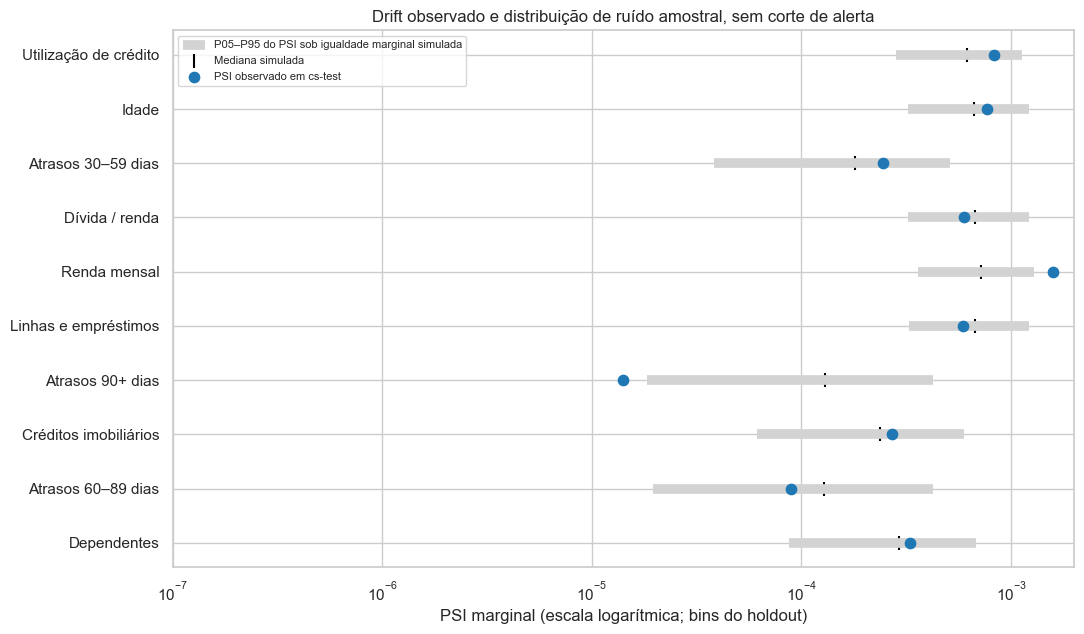

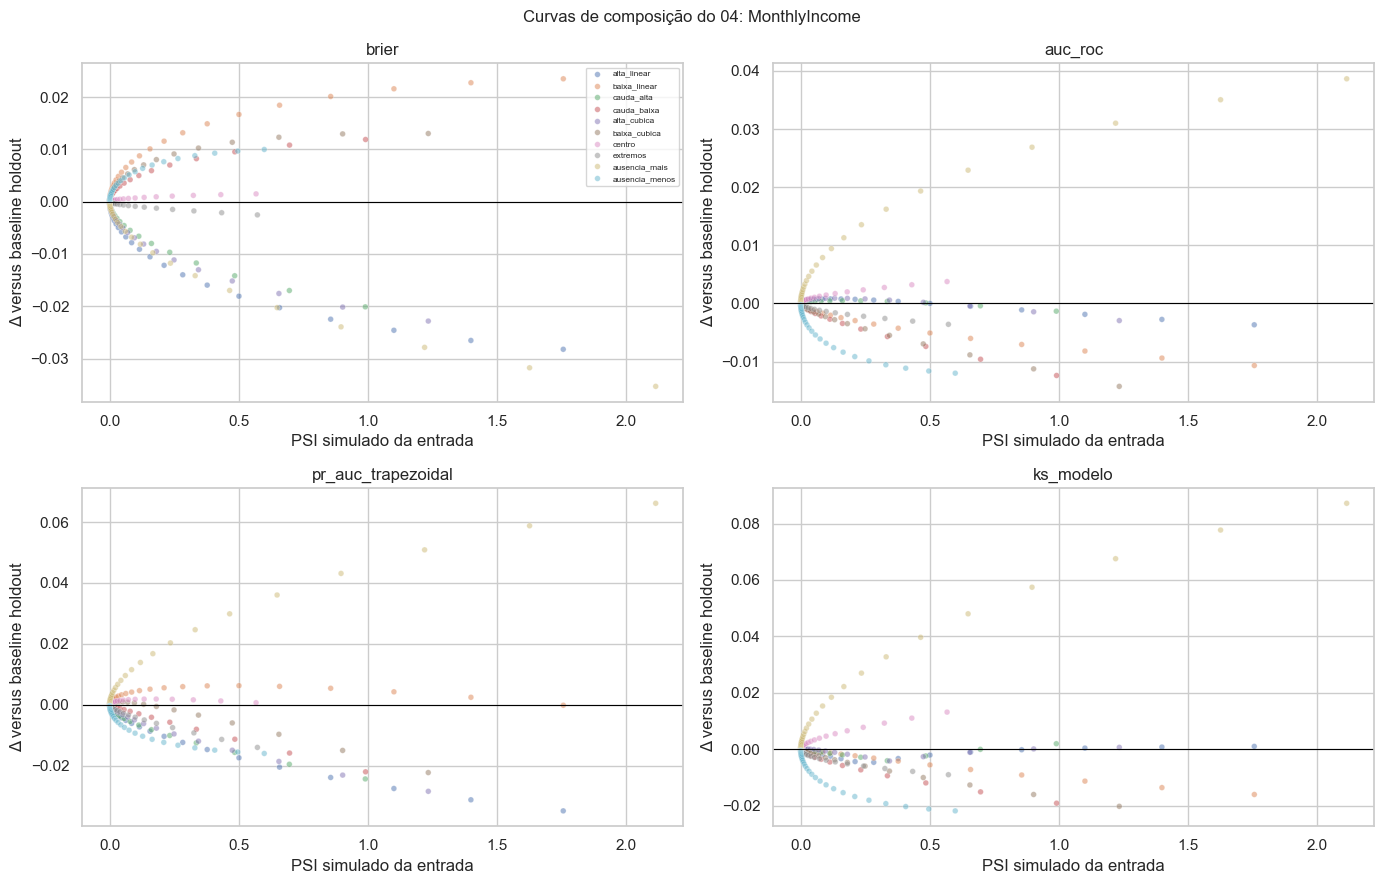

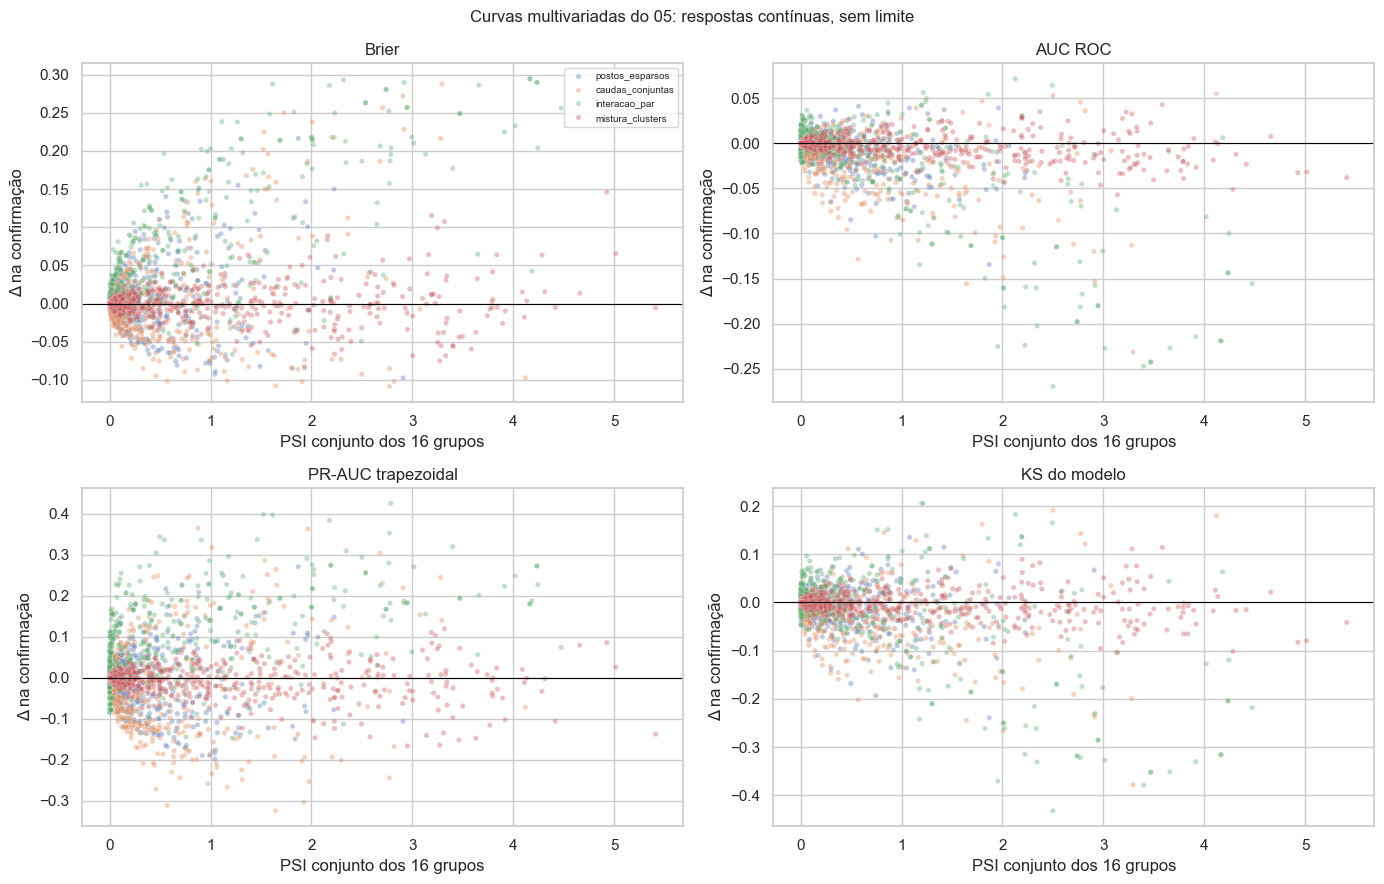

In [7]:
fig,ax=plt.subplots(figsize=(11,6.5))
plot=monitor[monitor.variavel!='score_modelo'].copy().iloc[::-1]
rotulos={
    'RevolvingUtilizationOfUnsecuredLines':'Utilização de crédito',
    'age':'Idade','NumberOfTime30-59DaysPastDueNotWorse':'Atrasos 30–59 dias',
    'DebtRatio':'Dívida / renda','MonthlyIncome':'Renda mensal',
    'NumberOfOpenCreditLinesAndLoans':'Linhas e empréstimos',
    'NumberOfTimes90DaysLate':'Atrasos 90+ dias',
    'NumberRealEstateLoansOrLines':'Créditos imobiliários',
    'NumberOfTime60-89DaysPastDueNotWorse':'Atrasos 60–89 dias',
    'NumberOfDependents':'Dependentes'}
ypos=np.arange(len(plot))
ax.hlines(ypos,plot.psi_nulo_p05,plot.psi_nulo_p95,color='lightgray',lw=7,
          label='P05–P95 do PSI sob igualdade marginal simulada')
ax.scatter(plot.psi_nulo_mediana,ypos,marker='|',color='black',s=100,label='Mediana simulada')
ax.scatter(plot.psi_observado,ypos,color='tab:blue',s=55,label='PSI observado em cs-test',zorder=3)
ax.set_yticks(ypos,plot.variavel.map(rotulos))
ax.set_xscale('log')
ax.set_xlim(left=1e-7)
ax.set(xlabel='PSI marginal (escala logarítmica; bins do holdout)',
       title='Drift observado e distribuição de ruído amostral, sem corte de alerta')
ax.legend(fontsize=8)
fig.tight_layout();plt.show()

foco=monitor[monitor.variavel!='score_modelo'].nlargest(1,'psi_observado').variavel.iloc[0]
uni_foco=uni[uni.variavel==foco]
fig,axes=plt.subplots(2,2,figsize=(14,9))
for axis,(nome,col) in zip(axes.flat,central.items()):
    sns.scatterplot(data=uni_foco,x='psi_variavel',y=col,hue='trajetoria',
                    s=17,alpha=.5,legend=(nome=='brier'),ax=axis)
    axis.axhline(0,color='black',lw=.8)
    axis.set(title=nome,xlabel='PSI simulado da entrada',ylabel='Δ versus baseline holdout')
    if axis.get_legend() is not None: axis.legend(fontsize=6)
fig.suptitle('Curvas de composição do 04: '+foco,fontsize=12)
fig.tight_layout();plt.show()

multi=pd.read_csv(ARQUIVO_MULTI)
required_multi={'familia','psi_conjunto_16_clusters',
    'delta_brier_confirmacao','delta_auc_confirmacao',
    'delta_prauc_trap_confirmacao','delta_ks_modelo_confirmacao'}
assert required_multi.issubset(multi.columns),required_multi-set(multi.columns)
fig,axes=plt.subplots(2,2,figsize=(14,9))
colunas_multi=[('delta_brier_confirmacao','Brier'),('delta_auc_confirmacao','AUC ROC'),
               ('delta_prauc_trap_confirmacao','PR-AUC trapezoidal'),
               ('delta_ks_modelo_confirmacao','KS do modelo')]
for axis,(col,nome) in zip(axes.flat,colunas_multi):
    sns.scatterplot(data=multi,x='psi_conjunto_16_clusters',y=col,hue='familia',
                    alpha=.36,s=14,legend=(nome=='Brier'),ax=axis)
    axis.axhline(0,color='black',lw=.8)
    axis.set(xlabel='PSI conjunto dos 16 grupos',ylabel='Δ na confirmação',title=nome)
    if axis.get_legend() is not None: axis.legend(fontsize=7)
fig.suptitle('Curvas multivariadas do 05: respostas contínuas, sem limite',fontsize=12)
fig.tight_layout();plt.show()

## 6. Como replicar e usar quando houver produção

1. **Congelar:** versão do Booster, transformações, ordem das entradas, bins de referência, tratamento de faltantes e corte de decisão. Guardar período e tamanho da janela.
2. **Comparar distribuições:** PSI por entrada e score, médias, quantis, ausentes, suporte e direção do deslocamento. Repetir por segmentos relevantes; PSI perde sinal e relações entre variáveis.
3. **Ler as curvas existentes:** consultar 04/05 por família, intensidade, PSI realizado, ESS e **quatro** métricas. O painel resume cenários próximos em PSI, mas a semelhança de PSI isolada não autoriza predizer efeito em uma população sem rótulos.
4. **Medir desempenho quando o desfecho amadurecer:** Brier, AUC ROC, PR-AUC trapezoidal e KS; AP adicional; recall e precisão em 0,50 como referências. A seleção de rótulos em crédito pode enviesar a comparação se apenas contratos concedidos tiverem desfecho observável.
5. **Revisar validade externa:** o holdout é aleatório e histórico, não um período futuro. Os extremos de 04/05 são múltiplas buscas na mesma base; confirmação em safras posteriores é necessária para interpretar tolerância operacional.

Este notebook não define limiares de parada. Uma política de monitoramento exige custos, horizonte de rótulo e materialidade aprovados no contexto de uso; tais valores não podem ser deduzidos do PSI isoladamente.